In [21]:
from sklearn.decomposition import PCA
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

In [22]:
df=pd.read_csv("C:/Users/space/Desktop/datas/WineQT.csv")

In [23]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='str')

In [24]:
x=df.drop(['quality', 'Id'],axis=1)
y=df['quality']

In [25]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.3,random_state=42)

In [26]:
scalar=StandardScaler()
x_scale=pd.DataFrame(scalar.fit_transform(x),columns=x.columns)
print(x_scale)

      fixed acidity  volatile acidity  ...  sulphates   alcohol
0         -0.521580          0.939332  ...  -0.573658 -0.963382
1         -0.292593          1.941813  ...   0.130881 -0.593601
2         -0.292593          1.273492  ...  -0.045254 -0.593601
3          1.653789         -1.399789  ...  -0.456235 -0.593601
4         -0.521580          0.939332  ...  -0.573658 -0.963382
...             ...               ...  ...        ...       ...
1138      -1.151292         -0.118842  ...   0.541862  0.515741
1139      -0.865059          0.493785  ...   0.952843 -0.870937
1140      -1.208538          0.382399  ...  -0.456235  0.053515
1141      -1.380278          0.103932  ...   0.600574  0.700632
1142      -1.380278          0.633019  ...   0.307016 -0.223820

[1143 rows x 11 columns]


In [27]:
model=LogisticRegression(max_iter=2000)

In [30]:
rfe=RFE(estimator=model,n_features_to_select=10)
x_selected=rfe.fit_transform(x_scale,y)
x_train_ref=rfe.fit_transform(xtrain,ytrain)
x_test_rfe=rfe.transform(xtest)

c:\Users\space\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\space\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://s

In [32]:
model.fit(x_train_ref,ytrain)

c:\Users\space\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [33]:
ypred=model.predict(x_test_rfe)
print(ypred)

[5 5 5 5 6 7 5 5 6 5 7 6 5 6 6 5 6 6 5 6 6 6 5 6 5 5 6 6 5 5 6 5 7 6 5 5 5
 6 7 6 6 5 7 5 5 5 6 6 5 6 6 5 6 6 6 6 5 6 6 5 5 6 6 6 6 5 7 5 5 6 5 5 6 6
 5 5 6 6 5 5 5 5 6 5 5 6 6 5 6 5 5 5 5 5 5 5 5 6 6 5 6 6 5 6 5 5 6 6 6 6 6
 5 5 6 5 5 5 7 6 5 5 5 5 7 5 6 6 6 5 7 5 5 7 6 7 5 5 5 6 6 7 5 5 5 7 5 5 5
 5 5 6 5 6 5 6 6 5 6 6 6 6 5 6 6 6 5 6 6 6 5 6 6 5 5 5 5 6 6 6 5 6 5 6 5 5
 5 6 5 6 6 6 6 7 6 6 5 5 6 6 6 6 6 5 5 6 5 5 5 6 6 5 6 5 6 5 5 7 5 6 6 6 5
 5 6 5 6 5 5 6 6 6 6 5 5 6 7 5 6 5 5 6 6 6 5 6 6 5 6 6 5 5 5 6 6 5 6 7 5 5
 5 6 5 6 6 5 5 5 6 5 6 5 7 5 6 5 6 5 6 6 5 5 6 5 5 6 7 5 5 6 6 6 5 6 5 6 6
 6 5 6 5 5 6 6 5 5 5 7 6 7 6 5 6 5 5 6 5 5 5 6 5 5 6 5 5 5 6 6 5 5 5 6 5 5
 7 5 5 6 5 7 5 6 5 5]


In [34]:
print("Selected original features:", x.columns[rfe.support_])

Selected original features: Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'density', 'pH', 'sulphates',
       'alcohol'],
      dtype='str')


In [35]:
print("Ranking:", rfe.ranking_)

Ranking: [1 1 1 1 1 1 2 1 1 1 1]


In [36]:
print("Accuracy:", accuracy_score(ytest, ypred))

Accuracy: 0.6064139941690962


In [37]:
pca=PCA(n_components=0.95)
x_pca=pca.fit_transform(x_selected)
print(x_pca)

[[-1.51099723  0.56335052 -1.72560273 ...  0.08368974  0.22535283
  -0.00651782]
 [-0.83349395  1.9750766  -0.70835416 ...  0.74569832 -1.05904141
   0.54144   ]
 [-0.70721532  1.02534252 -1.04917815 ...  0.29629597 -0.73676199
   0.07858474]
 ...
 [-2.11645832  0.81747771  0.70287352 ... -0.1971209   0.33826634
   1.01328434]
 [-2.24372306  0.72732601  1.86535579 ...  0.50021647  0.01183716
   1.15639132]
 [-2.24056046  0.93987646  0.73718022 ...  0.22413675  0.26242437
   0.71763116]]


In [41]:
pca_df=pd.DataFrame(x_pca,columns=[f"PC{i+1}" for i in range(x_pca.shape[1])])
pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,-1.510997,0.563351,-1.725603,0.189323,0.926657,0.083690,0.225353,-0.006518
1,-0.833494,1.975077,-0.708354,0.439071,-0.784156,0.745698,-1.059041,0.541440
2,-0.707215,1.025343,-1.049178,0.385713,-0.332121,0.296296,-0.736762,0.078585
3,2.418163,0.019799,0.328415,-1.524189,0.033507,-0.681491,0.325118,-0.100120
4,-1.510997,0.563351,-1.725603,0.189323,0.926657,0.083690,0.225353,-0.006518


In [42]:
print("explained:",pca.explained_variance_ratio_)

explained: [0.30909126 0.18165841 0.15670401 0.11514381 0.06662382 0.06296161
 0.04654684 0.03445202]


In [43]:
pca.explained_variance_ratio_.sum()


np.float64(0.9731818012135027)

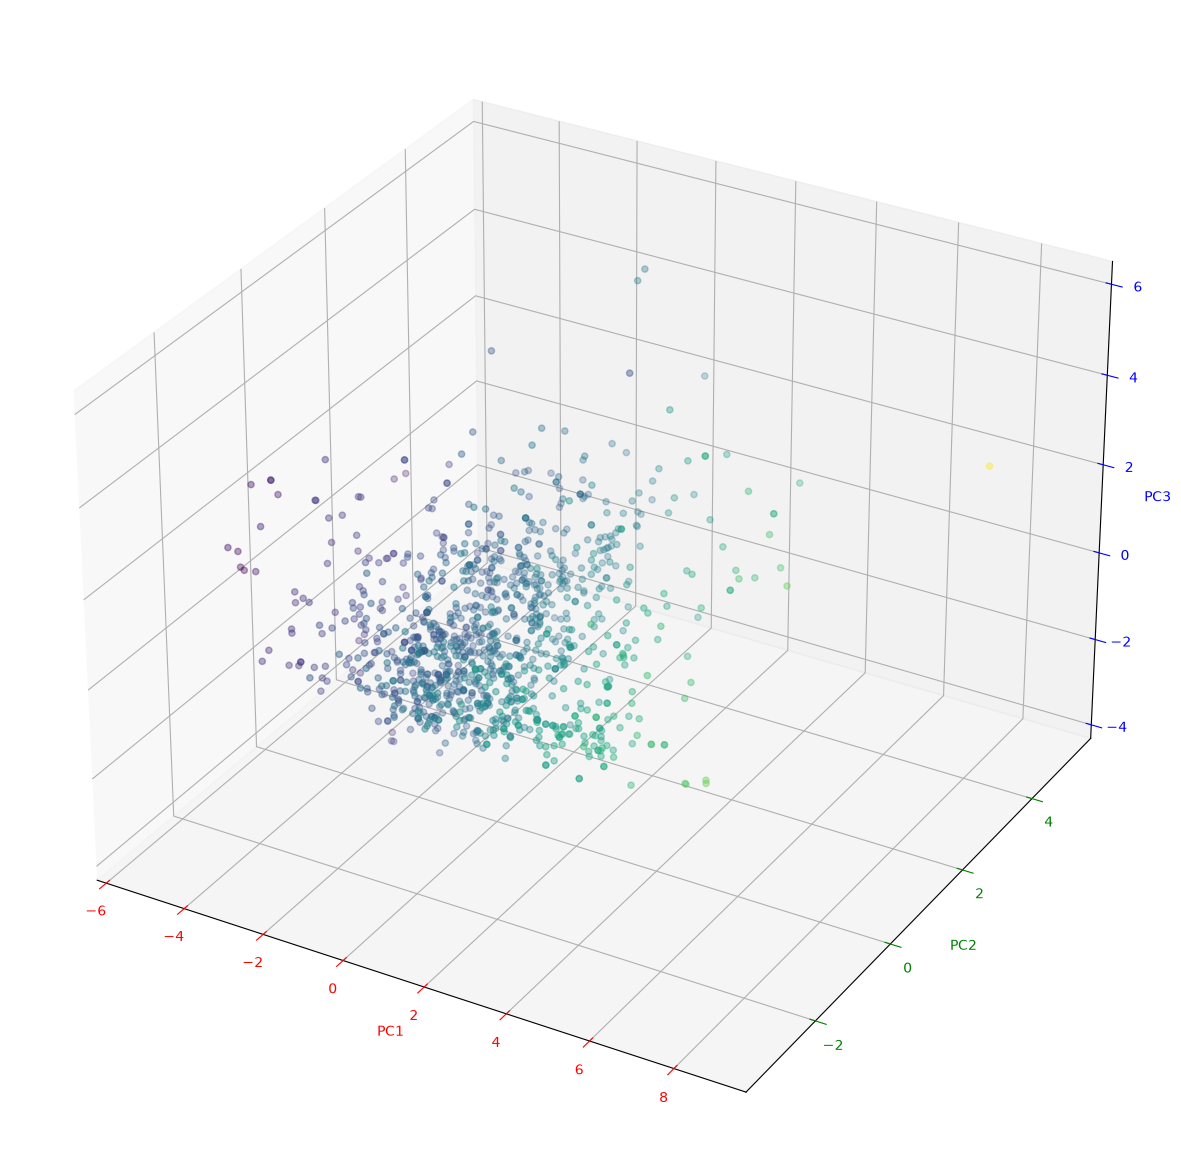

In [44]:
fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(pca_df['PC1'], pca_df['PC2'], pca_df['PC3'],c=pca_df["PC1"],cmap="viridis",alpha=0.7)
ax.set_xlabel("PC1", color="red")
ax.set_ylabel("PC2", color="green")
ax.set_zlabel("PC3", color="blue")

ax.tick_params(axis="x", colors="red")
ax.tick_params(axis="y", colors="green")
ax.tick_params(axis="z", colors="blue")
plt.show()